# CP-VTON(+) quick test: one sample from CPDataset → TryOnModel → visualize inputs/outputs
Этот ноутбук берёт **один** пример из датасета (где уже есть pose/agnostic/маски), прогоняет через `TryOnModel` из `tryon_infer.py` и показывает входы и выход.

⚠️ Мы **не меняем** `tryon_infer.py` — только импортируем и используем.


In [6]:
# !pip install matplotlib

In [9]:

import os
import torch
import matplotlib.pyplot as plt

# --- Пути: подстрой под себя ---
DATAROOT = "./data"  # корень датасета
GMM_CKPT = "/Users/pavel-esir/projects/cp-vton-plus/checkpoints/GMM/gmm_final.pth"
TOM_CKPT = "/Users/pavel-esir/projects/cp-vton-plus/checkpoints/TOM/tom_final.pth"

# Индекс примера из датасета
IDX = 1

# Устройство
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)


DEVICE: cpu


In [10]:

from cp_dataset import CPDataset
from tryon_infer import TryOnModel

# Мини-опции, чтобы CPDataset отработал так же, как в test.py (без argparse)
class Opt:
    dataroot = DATAROOT
    datamode = "test"
    data_list = "test_pairs.txt"
    fine_width = 192
    fine_height = 256
    radius = 5
    grid_size = 5

    stage = "TOM"
    shuffle = False

opt = Opt()

dataset = CPDataset(opt)
print("Dataset size:", len(dataset))


Dataset size: 2032


In [11]:

# Берём один экземпляр напрямую из dataset (без DataLoader)
sample = dataset[IDX]
print("agnostic:", sample["agnostic"].shape)
print("cloth:", sample["cloth"].shape)
print("cloth_mask:", sample["cloth_mask"].shape)

# Посмотрим, какие ключи есть
print("Keys:", list(sample.keys()))
for k, v in sample.items():
    if torch.is_tensor(v):
        print(f"{k:15s} tensor {tuple(v.shape)} dtype={v.dtype} min={v.min().item():.3f} max={v.max().item():.3f}")
    else:
        print(f"{k:15s} type={type(v)} value={v}")


agnostic: torch.Size([22, 256, 192])
cloth: torch.Size([3, 256, 192])
cloth_mask: torch.Size([1, 256, 192])
Keys: ['c_name', 'im_name', 'cloth', 'cloth_mask', 'image', 'agnostic', 'parse_cloth', 'shape', 'head', 'pose_image', 'grid_image', 'parse_cloth_mask', 'shape_ori']
c_name          type=<class 'str'> value=004325_1.jpg
im_name         type=<class 'str'> value=000010_0.jpg
cloth           tensor (3, 256, 192) dtype=torch.float32 min=-1.000 max=1.000
cloth_mask      tensor (1, 256, 192) dtype=torch.float32 min=0.000 max=1.000
image           tensor (3, 256, 192) dtype=torch.float32 min=-1.000 max=1.000
agnostic        tensor (22, 256, 192) dtype=torch.float32 min=-1.000 max=1.000
parse_cloth     tensor (3, 256, 192) dtype=torch.float32 min=-1.000 max=1.000
shape           tensor (1, 256, 192) dtype=torch.float32 min=-1.000 max=1.000
head            tensor (3, 256, 192) dtype=torch.float32 min=-1.000 max=1.000
pose_image      tensor (1, 256, 192) dtype=torch.float32 min=-1.000 max=1

In [12]:

# --- Утилиты визуализации тензоров ---
def to_img01(x: torch.Tensor):
    """
    Превращает tensor CHW или BCHW (в [-1,1] или [0,1]) в numpy HWC [0,1] для imshow.
    """
    if x is None:
        return None
    if x.dim() == 4:
        x = x[0]
    x = x.detach().float().cpu()
    # если похоже на [-1,1] — приведём к [0,1]
    if x.min() < -0.1:
        x = (x.clamp(-1, 1) + 1) * 0.5
    else:
        x = x.clamp(0, 1)
    if x.shape[0] == 1:
        x = x.repeat(3, 1, 1)
    x = x.permute(1, 2, 0).numpy()
    return x

def show_grid(title_to_tensor, cols=3, figsize=(12, 8)):
    items = []
    for title, v in title_to_tensor.items():
        if isinstance(v, torch.Tensor):
            items.append((title, v))
    
    rows = (len(items) + cols - 1) // cols
    plt.figure(figsize=figsize)
    for i, (title, tens) in enumerate(items, 1):
        plt.subplot(rows, cols, i)
        img = to_img01(tens)
        plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


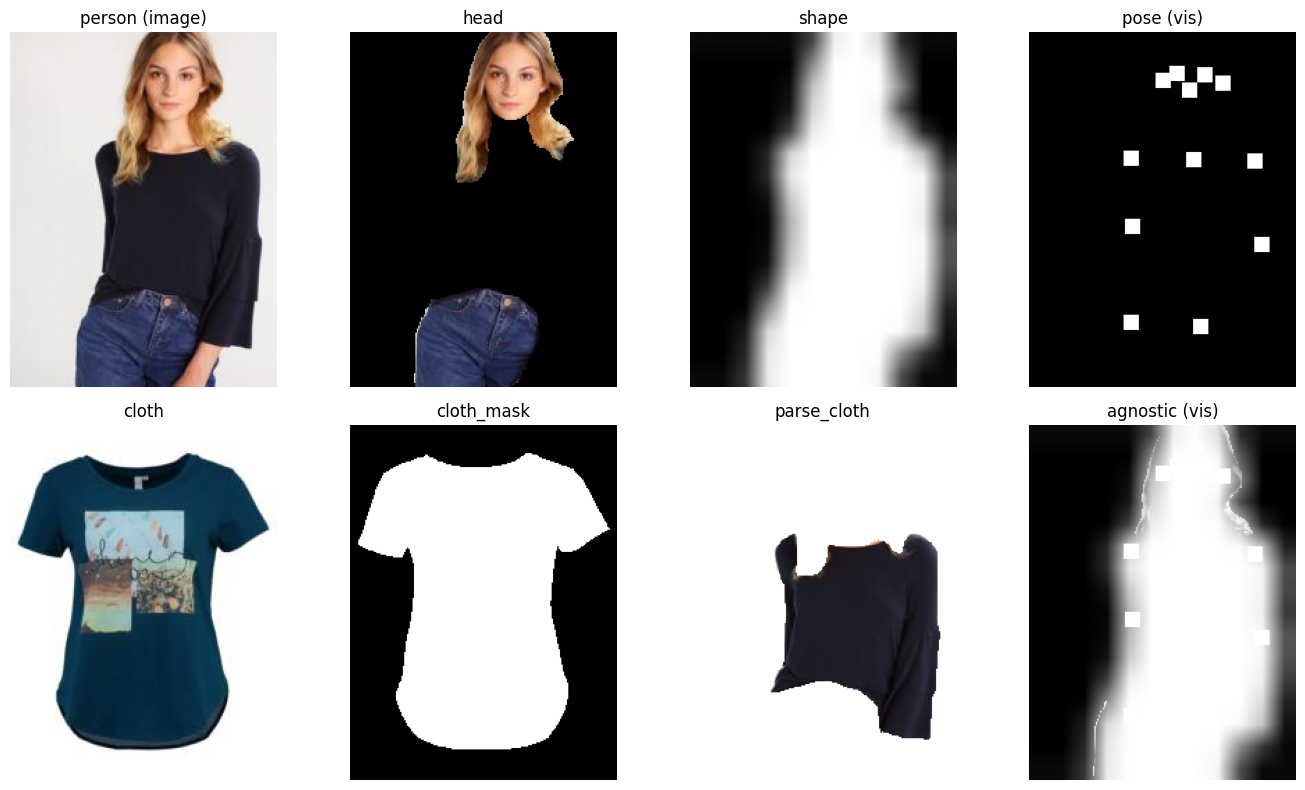

In [13]:

# Вытаскиваем тензоры из sample (как в test.py)
person_img  = sample.get("image")
pose_img    = sample.get("pose_image")
head_img    = sample.get("head")
shape       = sample.get("shape")
agnostic    = sample.get("agnostic")
cloth       = sample.get("cloth")
cloth_mask  = sample.get("cloth_mask")
parse_cloth = sample.get("parse_cloth")
grid_image  = sample.get("grid_image")

# Если pose многоканальный (heatmaps), для просмотра сделаем max по каналам
pose_vis = pose_img
if pose_vis is not None and torch.is_tensor(pose_vis) and pose_vis.shape[0] not in (1, 3):
    pose_vis = pose_vis.max(dim=0, keepdim=True).values

# agnostic тоже многоканальный — для просмотра сделаем max по каналам
agnostic_vis = agnostic
if agnostic_vis is not None and agnostic_vis.shape[0] not in (1, 3):
    agnostic_vis = agnostic_vis.max(dim=0, keepdim=True).values

show_grid({
    "person (image)": person_img,
    "head": head_img,
    "shape": shape,
    "pose (vis)": pose_vis,
    "cloth": cloth,
    "cloth_mask": cloth_mask,
    "parse_cloth": parse_cloth,
    "grid_image": grid_image,
    "agnostic (vis)": agnostic_vis,
}, cols=4, figsize=(14, 8))


In [14]:
# Подготовим batch (NCHW), как ожидает TryOnModel
agnostic_b = agnostic.unsqueeze(0)
cloth_b = cloth.unsqueeze(0)
cloth_mask_b = cloth_mask.unsqueeze(0)

# Инициализируем модель
model = TryOnModel(
    gmm_ckpt=GMM_CKPT,
    tom_ckpt=TOM_CKPT,
    device=DEVICE,
    use_fp16=False
)

# Инференс
out = model.tryon(agnostic_b, cloth_b, cloth_mask_b)  # [-1,1], shape [1,3,H,W]
print("Output shape:", out.shape, "min/max:", out.min().item(), out.max().item())


initialization method [normal]
initialization method [normal]
Output shape: torch.Size([1, 3, 256, 192]) min/max: -0.9912535548210144 0.9499917030334473


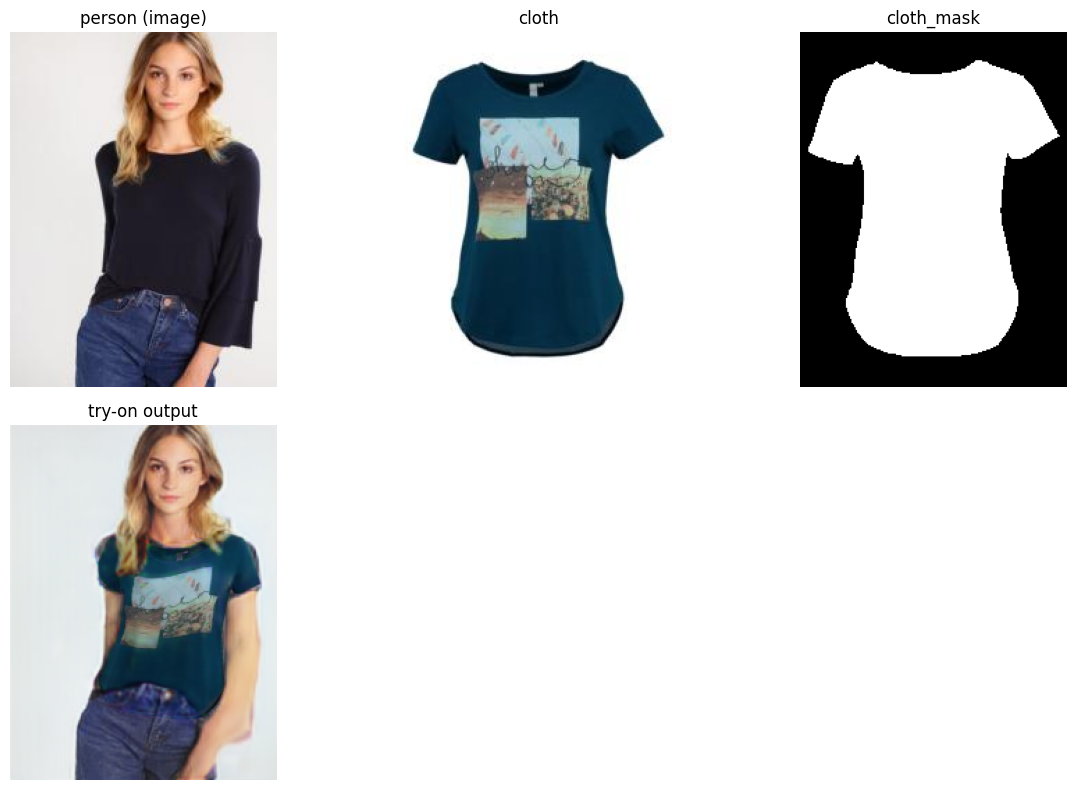

In [15]:

# Визуализация результата + (опционально) warped cloth/mask
# warped_cloth, warped_mask = model.warp_cloth(cloth_b, cloth_mask_b, agnostic_b)

show_grid({
    "person (image)": person_img,
    "cloth": cloth,
    "cloth_mask": cloth_mask,
    # "warped_cloth": warped_cloth,
    # "warped_mask": warped_mask,
    "try-on output": out,
}, cols=3, figsize=(12, 8))


## Как получить маски/позу/прочее из датасета для одного экземпляра
Самый простой способ:
```python
sample = dataset[IDX]
cloth_mask = sample['cloth_mask']
pose = sample['pose_image']
agnostic = sample['agnostic']
```

Если ключи отличаются — смотри вывод `Keys:` и подставь свои.
